# Tissue classification with PathMNIST

Small histology patches can contain very different tissue structures, even when they come from the same organ. This notebook uses PathMNIST from [MedMNIST](https://github.com/MedMNIST/MedMNIST/) to train a classifier on colorectal histology images, inspect its errors, and visualise the regions associated with its predictions.

The H&E patches are labelled across nine categories: adipose tissue, background, debris, lymphocytes, mucus, smooth muscle, normal colon mucosa, cancer-associated stroma, and colorectal adenocarcinoma epithelium. The task is to distinguish these patch categories.

## Preparing the environment

MedMNIST provides the images and labels, while PyTorch handles model training. The Grad-CAM package is used later to visualise the model?s responses on individual patches.

In [1]:
# Setup Environment
!pip install medmnist grad-cam

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached scikit_image-0.26.0-cp314-cp314-win_amd64.whl.metadata (15 kB)
   ---------------------------------------- 0.0/43.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/43.8 MB ? eta -:--:--
   ---------------------------------------- 0.3/43.8 MB ? eta -:--:--
   ---------------------------------------- 0.5/43.8 MB 1.4 MB/s eta 0:00:31
   ---------------------------------------- 0.5/43.8 MB 1.4 MB/s eta 0:00:31
   ---------------------------------------- 0.5/43.8 MB 1.4 MB/s eta 0:00:31
    --------------------------------------- 0.8/43.8 MB 574.9 kB/s eta 0:01:15
    --------------------------------------- 1.0/43.8 MB 649.8 kB/s eta 0


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
import numpy as np

# Visualise a few random training images with their labels
import matplotlib.pyplot as plt


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
import torchvision.transforms as transforms
import torchvision.models as models
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import medmnist
from medmnist import INFO
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## Preparing the images

The dataset metadata supplies the Python class and tissue labels. The 28 ? 28-pixel patches are resized to 224 ? 224 and normalised with the ImageNet channel statistics used by the pretrained models. Resizing changes the input dimensions but does not add image detail.

Training and validation use 10% of their respective splits to keep this run manageable. The test split is kept in full. A few training images are displayed with their labels before fitting the model.

In [3]:
data_flag = 'pathmnist'
info = INFO[data_flag]
DataClass = getattr(medmnist, info['python_class'])

data_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = DataClass(split='train', transform=data_transform, download=True)
val_dataset = DataClass(split='val', transform=data_transform, download=True)
test_dataset = DataClass(split='test', transform=data_transform, download=True)

train_dataset, _ = random_split(train_dataset, [0.1, 0.9])
val_dataset, _ = random_split(val_dataset, [0.1, 0.9])

train_loader = DataLoader(dataset=train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=128, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=128, shuffle=False)

print(f"Train samples: {len(train_dataset)}, Val samples: {len(val_dataset)}, Test samples: {len(test_dataset)}")

100%|██████████| 206M/206M [12:38<00:00, 271kB/s]  


Train samples: 9000, Val samples: 1001, Test samples: 7180


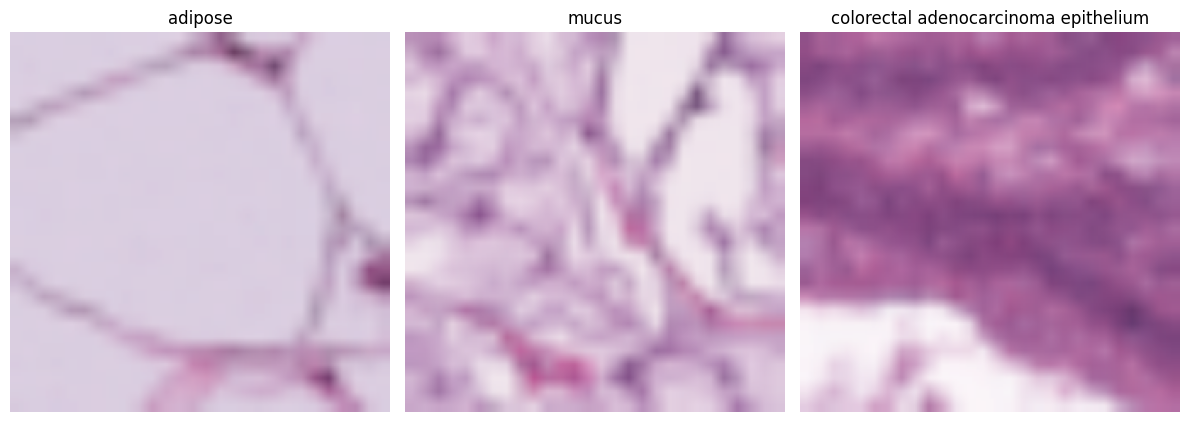

In [17]:

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

num_samples = 3
sample_indices = np.random.choice(len(train_dataset), num_samples, replace=False)

fig, axes = plt.subplots(1, 3, figsize=(12, 8))
for ax, idx in zip(axes.flat, sample_indices):
    img, label = train_dataset[idx]

    # Undo normalization for display
    img_viz = img.permute(1, 2, 0).numpy()
    img_viz = img_viz * std + mean
    img_viz = np.clip(img_viz, 0, 1)

    ax.imshow(img_viz)
    ax.set_title(info["label"][str(label.item())])
    ax.axis("off")

plt.tight_layout()
plt.show()

## Fine-tuning ResNet18

ResNet18 starts from ImageNet weights, with its final layer replaced by a classifier for the nine tissue categories. All model parameters are passed to Adam with a learning rate of 0.001.

The run lasts three epochs. Validation after each epoch helps compare progress on the training data with performance on held-out images.

In [18]:
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, len(info['label']))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 3
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for images, targets in train_loader:
        images = images.to(device)
        targets = targets.squeeze().long().to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_dataset)

    # Validation
    model.eval()
    val_correct = 0
    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)
            targets = targets.squeeze().long().to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            val_correct += torch.sum(preds == targets.data)

    val_acc = val_correct.double() / len(val_dataset)
    print(f"Epoch {epoch+1}/{num_epochs} - Train Loss: {epoch_loss:.4f} - Val Acc: {val_acc:.4f}")

Epoch 1/3 - Train Loss: 0.4722 - Val Acc: 0.8501
Epoch 2/3 - Train Loss: 0.2358 - Val Acc: 0.7263
Epoch 3/3 - Train Loss: 0.1727 - Val Acc: 0.9061


Time: 46 Mins

## Examining test predictions

Accuracy summarises how often the predicted label matches the reference label. Macro F1 gives each tissue category equal weight, and the confusion matrix makes recurring mix-ups between categories easier to see.

Test Accuracy: 0.8695
Test Macro F1: 0.8073


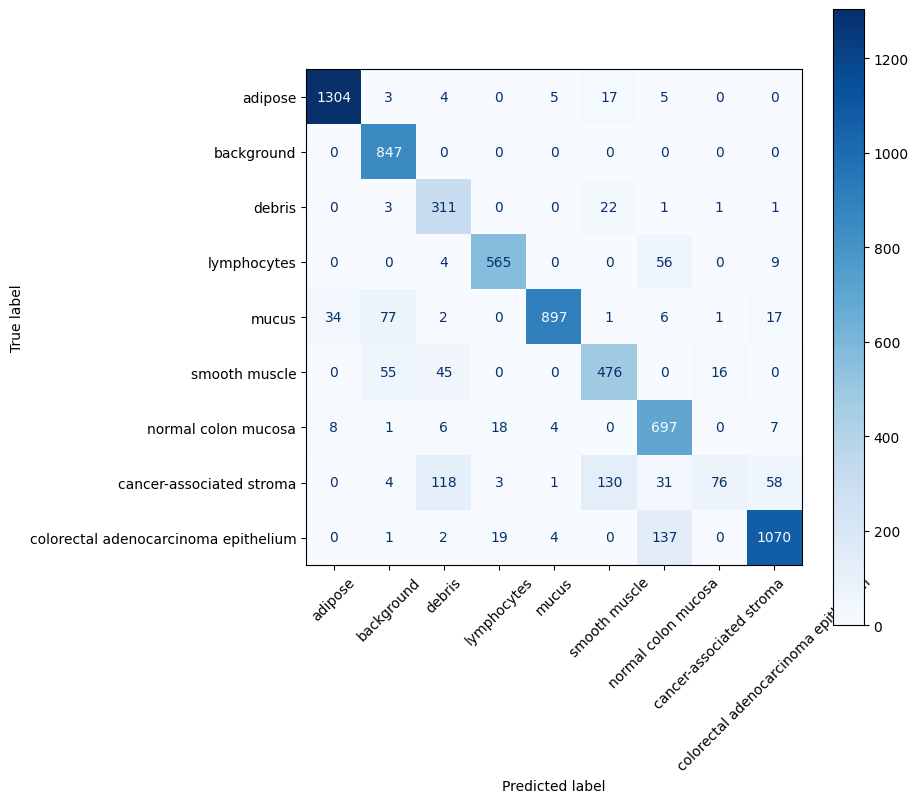

In [19]:
# EXERCISE 3: SOLUTION
model.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device)
        targets = targets.squeeze().long()
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        y_true.extend(targets.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

acc = accuracy_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred, average='macro')

print(f"Test Accuracy: {acc:.4f}")
print(f"Test Macro F1: {f1:.4f}")

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(info['label'].values()))
fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, cmap='Blues', xticks_rotation=45)
plt.show()

## Looking at the model with Grad-CAM

Grad-CAM overlays highlight areas associated with the model?s response for the selected images. Viewing them alongside the original patches helps inspect what the classifier attends to, although the heatmaps alone do not establish why a prediction is correct.

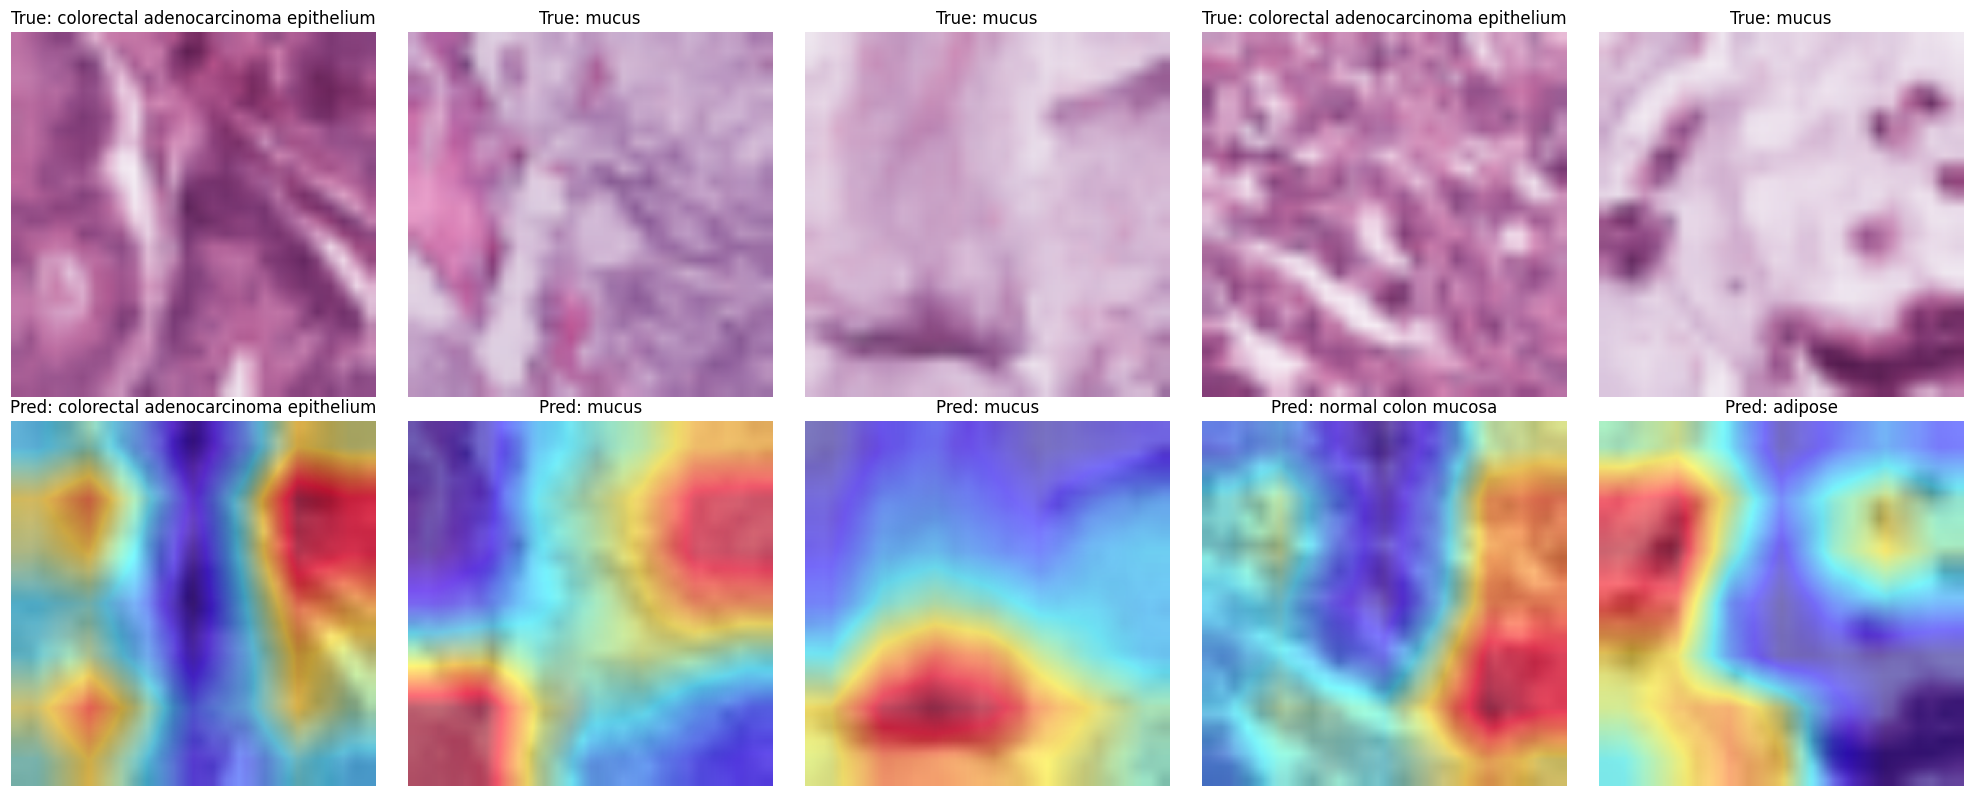

In [21]:
target_layers = [model.layer4[-1]]
cam = GradCAM(model=model, target_layers=target_layers)

class_names = list(info['label'].values())
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

for i in range(5):
    img_tensor, label = test_dataset[i]
    input_tensor = img_tensor.unsqueeze(0).to(device)

    # Get model prediction
    model.eval()
    with torch.no_grad():
        output = model(input_tensor)
        pred_idx = torch.argmax(output).item()

    # Generate CAM
    targets = [ClassifierOutputTarget(pred_idx)]
    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0, :]

    # Denormalize image for display
    img_viz = img_tensor.permute(1, 2, 0).numpy()
    img_viz = std * img_viz + mean
    img_viz = np.clip(img_viz, 0, 1)

    # Overlay CAM
    cam_image = show_cam_on_image(
        img_viz,
        grayscale_cam,
        use_rgb=True
    )

    # First row: Original images
    axes[0, i].imshow(img_viz)
    axes[0, i].set_title(
        f"True: {class_names[label.item()]}"
    )
    axes[0, i].axis("off")

    # Second row: Grad-CAM
    axes[1, i].imshow(cam_image)
    axes[1, i].set_title(
        f"Pred: {class_names[pred_idx]}"
    )
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

## Comparing other architectures

The following cells train EfficientNet-B0 and ViT-B/16 on the same prepared data, using ImageNet weights and classification heads adapted to PathMNIST. This provides another way to explore the task beyond ResNet18.

EfficientNet-B0 is evaluated with the same test metrics and visualised with Grad-CAM. The ViT section trains the model and records validation accuracy. Comparing final test performance across all three models would also require evaluating ViT on the test split.

In [22]:
# EfficientNet-B0
model_eff = models.efficientnet_b0(
    weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1
)

# Replace classification head for PathMNIST (9 classes)
num_ftrs = model_eff.classifier[1].in_features
model_eff.classifier[1] = nn.Linear(num_ftrs, len(info["label"]))

model_eff = model_eff.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_eff.parameters(), lr=0.001)

num_epochs = 3

for epoch in range(num_epochs):

    # Training
    model_eff.train()
    running_loss = 0.0

    for images, targets in train_loader:
        images = images.to(device)
        targets = targets.squeeze().long().to(device)

        optimizer.zero_grad()

        outputs = model_eff(images)
        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_dataset)

    # Validation
    model_eff.eval()
    val_correct = 0

    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)
            targets = targets.squeeze().long().to(device)

            outputs = model_eff(images)
            _, preds = torch.max(outputs, 1)

            val_correct += torch.sum(preds == targets)

    val_acc = val_correct.double() / len(val_dataset)

    print(
        f"Epoch {epoch+1}/{num_epochs} - "
        f"Train Loss: {epoch_loss:.4f} - "
        f"Val Acc: {val_acc:.4f}"
    )

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\Mahugnon/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:44<00:00, 485kB/s]


Epoch 1/3 - Train Loss: 0.4003 - Val Acc: 0.9271
Epoch 2/3 - Train Loss: 0.1445 - Val Acc: 0.9640
Epoch 3/3 - Train Loss: 0.0899 - Val Acc: 0.9500


Time: 90 Mins

### EfficientNet-B0 results

The trained EfficientNet-B0 model is evaluated on the test images below, followed by Grad-CAM views of a few patches.

EfficientNet-B0 Test Accuracy: 0.8843
EfficientNet-B0 Test Macro F1: 0.8416


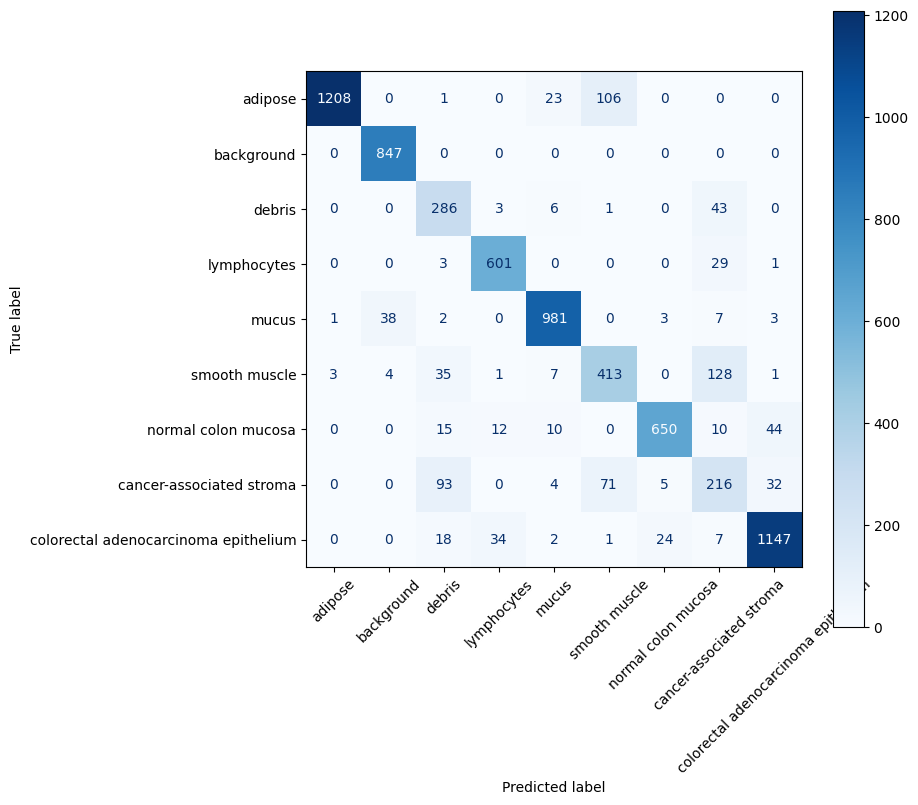

In [23]:
model_eff.eval()

y_true_eff = []
y_pred_eff = []

with torch.no_grad():
    for images, targets in test_loader:

        images = images.to(device)
        targets = targets.squeeze().long()

        outputs = model_eff(images)
        _, preds = torch.max(outputs, 1)

        y_true_eff.extend(targets.numpy())
        y_pred_eff.extend(preds.cpu().numpy())

acc_eff = accuracy_score(y_true_eff, y_pred_eff)
f1_eff = f1_score(y_true_eff, y_pred_eff, average="macro")

print(f"EfficientNet-B0 Test Accuracy: {acc_eff:.4f}")
print(f"EfficientNet-B0 Test Macro F1: {f1_eff:.4f}")

cm = confusion_matrix(y_true_eff, y_pred_eff)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(info["label"].values())
)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.show()

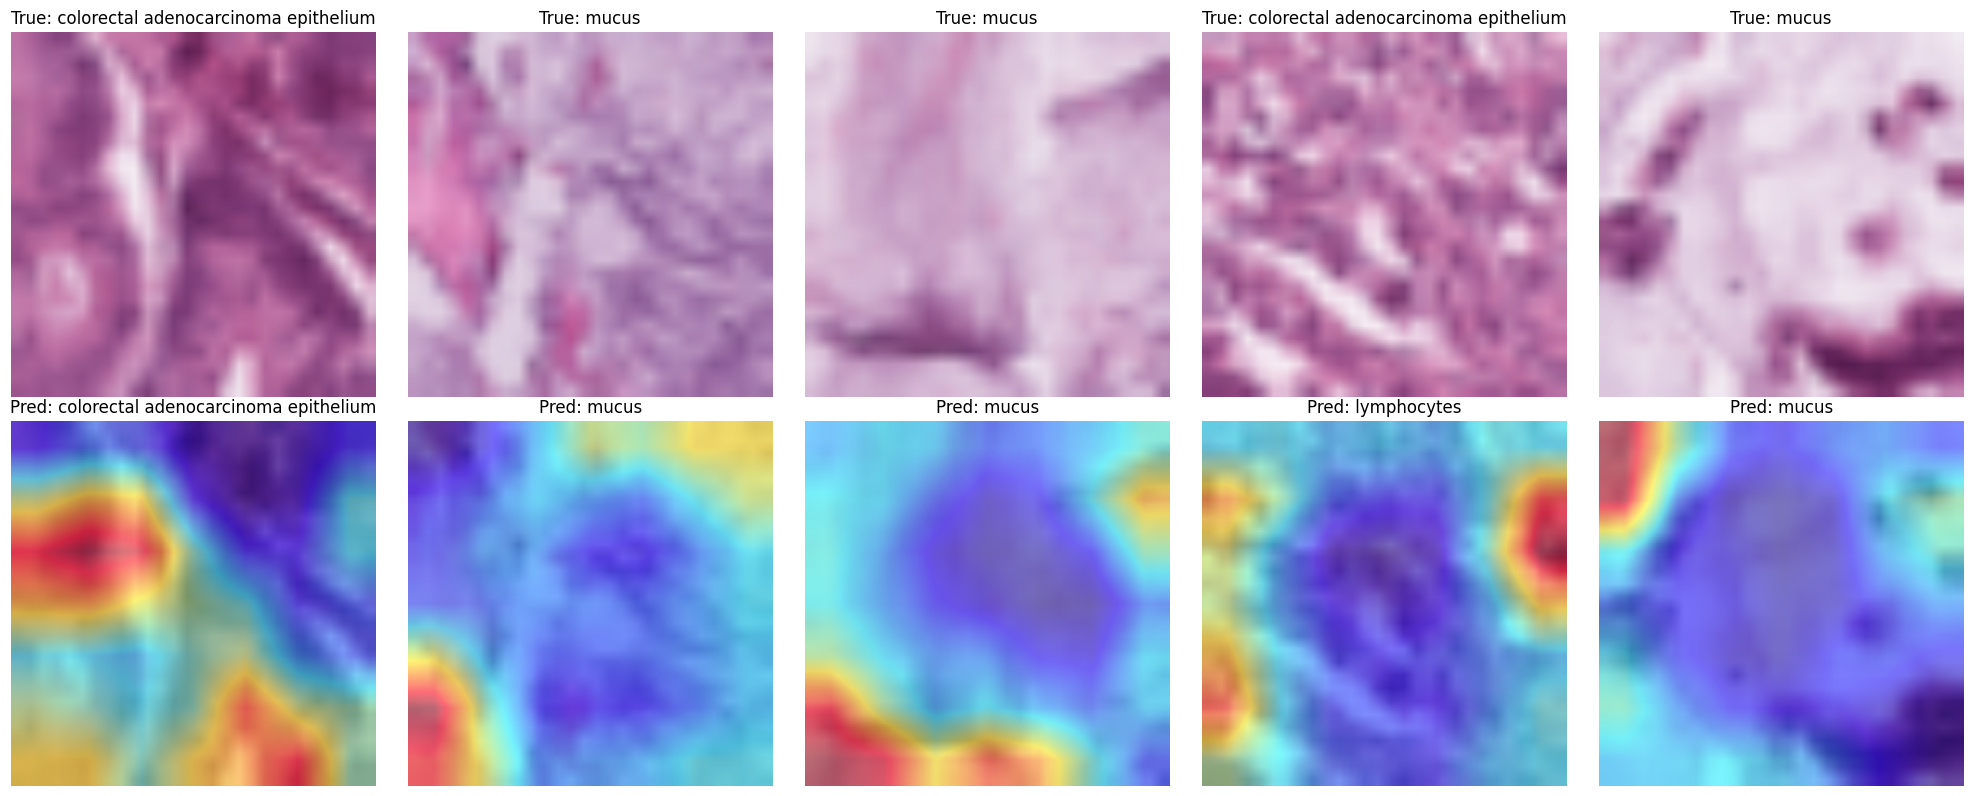

In [24]:
target_layers = [model_eff.features[-1]]

cam_eff = GradCAM(
    model=model_eff,
    target_layers=target_layers
)

class_names = list(info["label"].values())

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

for i in range(5):

    img_tensor, label = test_dataset[i]
    input_tensor = img_tensor.unsqueeze(0).to(device)

    # Prediction
    model_eff.eval()

    with torch.no_grad():
        output = model_eff(input_tensor)
        pred_idx = torch.argmax(output).item()

    # Grad-CAM
    targets = [ClassifierOutputTarget(pred_idx)]

    grayscale_cam = cam_eff(
        input_tensor=input_tensor,
        targets=targets
    )[0, :]

    # Undo ImageNet normalization
    img_viz = img_tensor.permute(1, 2, 0).numpy()
    img_viz = std * img_viz + mean
    img_viz = np.clip(img_viz, 0, 1)

    # Overlay
    cam_image = show_cam_on_image(
        img_viz,
        grayscale_cam,
        use_rgb=True
    )

    # Row 1: original
    axes[0, i].imshow(img_viz)
    axes[0, i].set_title(
        f"True: {class_names[label.item()]}"
    )
    axes[0, i].axis("off")

    # Row 2: Grad-CAM
    axes[1, i].imshow(cam_image)
    axes[1, i].set_title(
        f"Pred: {class_names[pred_idx]}"
    )
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [25]:
from torchvision import models
import torch.nn as nn
import torch.optim as optim

# ViT-B/16 pretrained on ImageNet
model_vit = models.vit_b_16(
    weights=models.ViT_B_16_Weights.IMAGENET1K_V1
)

# Replace classification head for PathMNIST
num_ftrs = model_vit.heads.head.in_features
model_vit.heads.head = nn.Linear(num_ftrs, len(info["label"]))

model_vit = model_vit.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_vit.parameters(), lr=1e-4)

num_epochs = 3

for epoch in range(num_epochs):

    model_vit.train()
    running_loss = 0.0

    for images, targets in train_loader:
        images = images.to(device)
        targets = targets.squeeze().long().to(device)

        optimizer.zero_grad()

        outputs = model_vit(images)
        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_dataset)

    # Validation
    model_vit.eval()
    correct = 0

    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)
            targets = targets.squeeze().long().to(device)

            outputs = model_vit(images)
            preds = outputs.argmax(dim=1)

            correct += (preds == targets).sum().item()

    val_acc = correct / len(val_dataset)

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Loss: {train_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to C:\Users\Mahugnon/.cache\torch\hub\checkpoints\vit_b_16-c867db91.pth


100%|██████████| 330M/330M [10:29<00:00, 550kB/s] 


Epoch 1/3 | Loss: 0.4819 | Val Acc: 0.9391


: 

Time: More than 200 Mins and the Kernel crashed